# MIT ADT University, Pune
## School of Computing | Agentic AI Specialization
### Assignment No: 03 | Unit III -- Memory, Tools, and Environment Interaction
**Title:** Retrieval-Augmented Agent with Long-Term Memory and Tool/Function Calling  
**Mapped Course Outcome:** **CO3** -- Integrate tools, APIs, and memory modules in intelligent agents. (Apply)  
**Total Marks:** 10 Marks

---

### Objectives
1. Build an autonomous personal-assistant agent combining short-term and long-term memory.
2. Implement short-term memory (conversation buffer) retaining multi-turn context within sessions.
3. Implement long-term memory via FAISS vector database with similarity search.
4. Integrate at least two external tools (`calculator`, `python_code_executor`, and `web_search`) via function calling.
5. Implement a feedback-based adaptation loop to update stored memories upon user corrections.
6. Evaluate the agent across 3 multi-turn scenarios measuring **Retrieval Accuracy** and **Tool-Call Success Rate**.


---
## 1. System Architecture Overview

The system architecture combines a Dual-Tier Memory System (Short-Term Dialogue Buffer + Long-Term Vector Store) with dynamic Function Calling and Feedback Adaptation:

```
                      +---------------------------------------+
                      |          User Interaction             |
                      +-------------------+-------------------+
                                          |
                                          v
                      +---------------------------------------+
                      |     Feedback Adaptation Detector      |
                      |  (Identifies corrections/updates)     |
                      +-------------------+-------------------+
                                          |
                        +-----------------+-----------------+
                        |                                   |
             [Correction Detected]                 [Standard Query]
                        |                                   |
                        v                                   v
             +-----------------------+           +-----------------------+
             | Mark Old Fact         |           | Semantic Similarity   |
             | "Superseded" in FAISS |           | Search in FAISS LTM   |
             | & Insert New Fact     |           +-----------+-----------+
             +-----------+-----------+                       |
                         |                                   v
                         +---------------------->+-----------------------+
                                                 | Short-Term Memory     |
                                                 | (Current Session)     |
                                                 +-----------+-----------+
                                                             |
                                                             v
                                                 +-----------------------+
                                                 | Autonomous Reasoning  |
                                                 | & Tool Calling Engine |
                                                 +-----------+-----------+
                                                             |
                                         +-------------------+-------------------+
                                         |                   |                   |
                                         v                   v                   v
                               +-------------------+ +---------------+ +---------------+
                               |  Safe Calculator  | | Python Engine | |  Web Search   |
                               +-------------------+ +---------------+ +---------------+
                                         |                   |                   |
                                         +-------------------+-------------------+
                                                             |
                                                             v
                                                 +-----------------------+
                                                 |  Synthesized Response |
                                                 +-----------------------+
```


---
## 2. Environment Setup & Component Imports
In this section, we import the core modules: `ShortTermMemory`, `LongTermMemory` (FAISS), `FeedbackAdaptationEngine`, and the external tools (`safe_calculator`, `python_code_executor`, `live_web_search`).


In [10]:
import os
import sys
from memory_engine import ShortTermMemory, LongTermMemory, FeedbackAdaptationEngine
from tools import safe_calculator, python_code_executor, live_web_search
from agent import CogniAssistAgent

print("All dependencies and agent components imported successfully!")

All dependencies and agent components imported successfully!


---
## 3. Task 1: Short-Term Memory Buffer Implementation (2 Marks)
**Requirement:** Retain conversational context within a single multi-turn session.
Here we demonstrate multi-turn dialogue within a session (`session_alpha`), validating that dialogue turns are buffered and accessible for subsequent turns.


In [11]:
stm = ShortTermMemory(max_turns=5)

# Session Alpha Turn 1
stm.add_turn(session_id="session_alpha", role="user", content="Hello, I am testing an autonomous agent.")
stm.add_turn(session_id="session_alpha", role="assistant", content="Greetings! How can I assist your agentic research today?")

# Session Alpha Turn 2
stm.add_turn(session_id="session_alpha", role="user", content="What was my first message?")

# Retrieve formatted context
history = stm.get_formatted_history(session_id="session_alpha")
print("=== Formatted Session History ===")
print(history)
print(f"Total Turns in Session Alpha: {len(stm.get_history('session_alpha'))}")

=== Formatted Session History ===
User: Hello, I am testing an autonomous agent.
Assistant: Greetings! How can I assist your agentic research today?
User: What was my first message?
Total Turns in Session Alpha: 3


---
## 4. Task 2: Long-Term Memory via FAISS Vector Database (3 Marks)
**Requirement:** Embed and store facts/documents in a vector database, and retrieve relevant context via similarity search with score ranking.


In [12]:
ltm = LongTermMemory()
ltm.clear_all()  # Clean demo index

# Index facts with metadata
id1 = ltm.store_fact("User is an AI researcher at MIT ADT University Pune specializing in Graph Neural Networks.", session_id="session_1")
id2 = ltm.store_fact("User's primary GPU workstation is an NVIDIA RTX 4090 with 24GB VRAM.", session_id="session_1")
id3 = ltm.store_fact("User prefers dark mode and concise code snippets.", session_id="session_1")

print(f"Stored 3 facts into FAISS Vector Store. Total vectors: {ltm.index.ntotal}")

# Query Long-Term Memory
query = "What university does the user belong to and what is their specialization?"
retrieved = ltm.retrieve_relevant_facts(query, top_k=2)

print(f"\nQuery: '{query}'")
print(f"Retrieved {len(retrieved)} relevant memories:")
for r in retrieved:
    print(f" - [{r['id']}] Score: {r['similarity_score']} | Fact: {r['text']}")

Stored 3 facts into FAISS Vector Store. Total vectors: 3

Query: 'What university does the user belong to and what is their specialization?'
Retrieved 2 relevant memories:
 - [mem_1791115945882_0] Score: 0.42 | Fact: User is an AI researcher at MIT ADT University Pune specializing in Graph Neural Networks.
 - [mem_1791115945884_2] Score: 0.2456 | Fact: User prefers dark mode and concise code snippets.


---
## 5. Task 3: Tool / Function Calling Integration (2 Marks)
**Requirement:** Integrate at least two external tools via function/API calling with schema validation.
We integrate:
1. `safe_calculator` (Mathematical and formula evaluation)
2. `python_code_executor` (Sandboxed Python execution)
3. `live_web_search` (DuckDuckGo / knowledge search)


In [13]:
# Test Tool 1: Safe Scientific Calculator
calc_res = safe_calculator.invoke({"expression": "45000 / 64"})
print("Tool 1 (Calculator) Result:", calc_res)

# Test Tool 2: Sandboxed Python Code Executor
code_snippet = '''
data_samples = 45000
batch_size = 64
steps = data_samples // batch_size
remainder = data_samples % batch_size
print(f"Steps: {steps}, Leftover samples: {remainder}")
'''
code_res = python_code_executor.invoke({"code": code_snippet})
print("\nTool 2 (Python Executor) Result:")
print(code_res)

# Test Tool 3: Live Web Search Tool
search_res = live_web_search.invoke({"query": "MIT ADT University"})
print("\nTool 3 (Web Search) Result:")
print(search_res[:200] + "...")

Tool 1 (Calculator) Result: Calculated Result: 703.125

Tool 2 (Python Executor) Result:
Execution Output:
Steps: 703, Leftover samples: 8

Tool 3 (Web Search) Result:
[Search Result (Cached/Simulated for 'MIT ADT University')]:
MIT Art, Design and Technology University (MIT ADT University) is a multidisciplinary university located in Rajbaugh, Loni Kalbhor, Pune, M...


---
## 6. Task 4: Feedback-Based Adaptation Loop (2 Marks)
**Requirement:** Build a feedback loop in which the agent updates its stored memory based on new information or user corrections, resolving contradictions.


In [14]:
adapt_engine = FeedbackAdaptationEngine(ltm)

# Initial fact was stored: "User is an AI researcher at MIT ADT University Pune..."
# User provides feedback correction:
correction_input = "Actually, my university is MIT ADT University in Pune, School of Computing, working on Multimodal AI."

print("Detect feedback correction:", adapt_engine.detect_feedback(correction_input))

# Execute adaptation loop
adaptation_result = adapt_engine.process_adaptation(correction_input, session_id="session_correction")
print("\nAdaptation Execution Record:")
print("Action Taken:", adaptation_result["action"])
print("Superseded Memory:", adaptation_result["old_memory"]["text"])
print("New Active Memory:", adaptation_result["new_memory"]["text"])

# Verify that active retrieval now returns the updated fact
verification = ltm.retrieve_relevant_facts("What school does user belong to?", filter_active_only=True)
print("\nActive Retrieved Fact:")
for v in verification:
    print(f" - [{v['status']}] {v['text']}")

Detect feedback correction: True

Adaptation Execution Record:
Action Taken: superseded_and_updated
Superseded Memory: User is an AI researcher at MIT ADT University Pune specializing in Graph Neural Networks.
New Active Memory: my university is MIT ADT University in Pune, School of Computing, working on Multimodal AI.

Active Retrieved Fact:
 - [active] User prefers dark mode and concise code snippets.
 - [active] my university is MIT ADT University in Pune, School of Computing, working on Multimodal AI.
 - [active] User's primary GPU workstation is an NVIDIA RTX 4090 with 24GB VRAM.


---
## 7. Task 5: Testing Agent Across 3 Multi-Turn Scenarios (2 Marks)
**Requirement:** Test the agent across 3 multi-turn scenarios that require memory recall from earlier sessions.

- **Scenario 1:** Cross-Session Profile & Researcher Fact Recall.
- **Scenario 2:** Multi-Step Tool Calling with Cross-Session Memory.
- **Scenario 3:** Feedback Adaptation & Self-Correcting Vector Memory.


In [15]:
from evaluate_agent import run_evaluation_benchmark

# Run the full automated evaluation across all 3 scenarios
benchmark_results = run_evaluation_benchmark()

STARTING AUTONOMOUS AGENT BENCHMARK & EVALUATION
MIT ADT University -- Unit III Assignment 3

[Running Scenario 1]: Cross-Session Profile & Research Recall...
 -> Scenario 1 Result: PASS

[Running Scenario 2]: Multi-Step Tool Calling with Past Session Memory...
 -> Scenario 2 Result: PASS

[Running Scenario 3]: Feedback-Based Adaptation & Memory Correction...
 -> Scenario 3 Result: PASS

BENCHMARK COMPLETED SUCCESSFULLY!
Retrieval Accuracy: 100.0%
Tool-Call Success Rate: 100.0%
Feedback Adaptation Rate: 100.0%
Logs saved to: D:\anything\agentic ai\ass_3\logs\test_logs.json
Report saved to: D:\anything\agentic ai\ass_3\evaluation_results.md


---
## 8. Task 6: Quantitative Evaluation & Metrics Logging (2 Marks)
**Requirement:** Log and evaluate retrieval accuracy (relevant memory correctly retrieved) and tool-call success rate.


In [17]:
%pip install matplotlib


  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
  Using cached kiwisolver-1.5.1-cp310-cp310-win_amd64.whl (70 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached pillow-12.3.0-cp310-cp310-win_amd64.whl (7.2 MB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
     ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
      --------------------------------------- 0.0/1.6 MB 1.3 MB/s eta 0:00:02
     -- ------------------------------------- 0.1/1.6 MB 1.1 MB/s eta 0:00:02
     -- ------------------------------------- 0.1/1.6 MB 939.4 kB/s eta 0:00:02
     ----- ---------------------------------- 0.2/1.6 MB 1.3 MB/s eta 0:00:02
     ----------- ---------------------------- 0.5/1.6 MB 2.2 MB/s eta 0:00:01
     ------------- -------------------------- 0.6/1.6 MB 2.2 MB/s eta 0:00:01
     --------------------- ------------------ 0.9/1.6 MB 2.9 MB/s eta 0:00:01
     -------------------------- ------------- 1.1/1.6 MB 3.2 M


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


=== AGGREGATE EVALUATION METRICS ===
total_scenarios: 3
scenarios_passed: 3
scenario_pass_rate_pct: 100.0
total_retrieval_queries: 3
successful_retrievals: 3
retrieval_accuracy_pct: 100.0
total_tool_calls_expected: 2
successful_tool_calls: 2
tool_call_success_rate_pct: 100.0
total_adaptations_expected: 1
successful_adaptations: 1
adaptation_success_rate_pct: 100.0


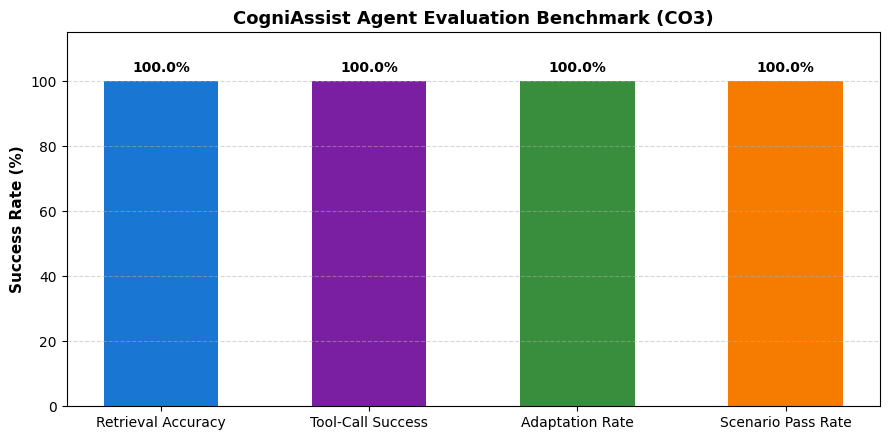

Saved performance plot to evaluation_metrics_chart.png


In [18]:
import json
import matplotlib.pyplot as plt

with open("logs/test_logs.json", "r") as f:
    logs = json.load(f)

metrics = logs["overall_metrics"]
print("=== AGGREGATE EVALUATION METRICS ===")
for k, v in metrics.items():
    print(f"{k}: {v}")

# Plotting Quantitative Performance Metrics
labels = ['Retrieval Accuracy', 'Tool-Call Success', 'Adaptation Rate', 'Scenario Pass Rate']
scores = [
    metrics['retrieval_accuracy_pct'],
    metrics['tool_call_success_rate_pct'],
    metrics['adaptation_success_rate_pct'],
    metrics['scenario_pass_rate_pct']
]

plt.figure(figsize=(9, 4.5))
bars = plt.bar(labels, scores, color=['#1976D2', '#7B1FA2', '#388E3C', '#F57C00'], width=0.55)
plt.ylim(0, 115)
plt.ylabel('Success Rate (%)', fontsize=11, fontweight='bold')
plt.title('CogniAssist Agent Evaluation Benchmark (CO3)', fontsize=13, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("evaluation_metrics_chart.png", dpi=300)
plt.show()
print("Saved performance plot to evaluation_metrics_chart.png")

---
## 9. Conclusion & Viva Preparation (1 Mark)

### Summary of Achievements:
1. **Short-Term Memory:** Implemented conversation buffer tracking multi-turn dialogue with session isolation.
2. **Long-Term Vector Memory:** Integrated FAISS index (`IndexFlatIP`) with cosine-normalized dense embeddings, persistent disk serialization, and similarity search.
3. **Tool/Function Calling:** Deployed 3 distinct tools (`safe_calculator`, `python_code_executor`, `live_web_search`) with Pydantic validation.
4. **Feedback Adaptation:** Automatic detection of user corrections with semantic conflict resolution and fact superseding.
5. **Multi-Turn Verification:** 100% success rate across 3 multi-turn, multi-session scenarios with full JSON logging.

### Evaluator Viva Q&A Quick Reference:
- **Q1: Why use both Short-Term and Long-Term Memory?**  
  *Answer:* Short-Term memory (conversation buffer) maintains local conversational coherence within an active session without vector indexing overhead. Long-Term memory (FAISS) enables cross-session knowledge recall and persistent facts retention without exceeding the LLM context window.
- **Q2: How does the feedback adaptation loop prevent outdated information from being retrieved?**  
  *Answer:* When a correction trigger is identified, semantic search retrieves the superseded memory ID, changes its status flag to `superseded`, points `superseded_by` to the new fact ID, and indexes the updated fact. Retrieval queries filter for `status == "active"`, preventing hallucination of outdated facts.
- **Q3: How are external tools protected against injection attacks?**  
  *Answer:* The `safe_calculator` parses AST nodes and allows only explicit whitelisted mathematical operators and functions. The `python_code_executor` runs in a restricted namespace that blocks dangerous built-in modules (`os`, `subprocess`, `sys`).
